## Network Intrusion Detection and Attack Classification Using Machine Learning

## Introduction

With the rapid growth of internet connectivity and digital communication, network security has become an essential concern for organisations and individuals. Networks are increasingly exposed to various cyber threats, including Denial of Service (DoS), exploitation attempts, reconnaissance activities and other malicious attacks.

Traditional intrusion detection systems often rely on predefined rules and known attack signatures to identify suspicious network activities. However, these approaches may struggle to recognise unfamiliar attack patterns and adapt to evolving cyber threats.

Machine Learning provides an effective approach to analysing network traffic, identifying hidden patterns and classifying different types of network activities based on their characteristics.

This project focuses on developing and evaluating supervised machine learning classification models using the UNSW-NB15 dataset. The models will analyse network traffic features to distinguish normal activities from malicious traffic and identify specific categories of cyberattacks.

The project also compares the performance of multiple classification algorithms to determine their effectiveness in network intrusion detection.

## Problem Statement

The increasing frequency and complexity of cyberattacks make it challenging to maintain secure network environments. Traditional intrusion detection systems primarily depend on predefined rules and signatures, which may not effectively identify different types of malicious network activities.

Identifying suspicious network traffic and accurately distinguishing between various attack categories is therefore an important cybersecurity challenge.

This project aims to address this problem by developing machine learning classification models that analyse network traffic characteristics and classify them into normal or specific cyberattack categories using the UNSW-NB15 dataset.

## Project Objectives

The primary objectives of this project are:

1. To understand and analyse network traffic data and its characteristics.
2. To identify patterns associated with normal network activities and different cyberattack categories.
3. To perform data cleaning and preprocessing to prepare the dataset for machine learning.
4. To explore the distribution of network traffic and identify important features.
5. To develop multiple supervised machine learning classification models for network attack detection.
6. To evaluate and compare the performance of different classification algorithms using appropriate evaluation metrics.
7. To identify the most effective model for classifying network traffic and detecting cyberattacks.

## Dataset Overview

The UNSW-NB15 dataset is a widely used network intrusion detection benchmark dataset developed by the Cyber Range Lab at the University of New South Wales (UNSW), Canberra.

It was created to support research in network security and intrusion detection by providing network traffic records containing both normal activities and various types of cyberattacks.

The dataset contains **175,341 records and 45 columns**, including network traffic characteristics such as communication protocols, connection duration, packet information, data transfer rates and other traffic-related attributes.

For this project, the `UNSW_NB15_training-set.csv` file is selected as the primary data source. It contains network traffic records representing normal activities and nine different categories of cyberattacks.

The target variable, `attack_cat`, will be used to develop multiclass classification models that identify the category of each network traffic record.

## Classification Algorithms Used

Classification is a supervised machine learning technique used to predict categorical outcomes based on input features. Since the objective of this project is to identify and classify different categories of network traffic, classification algorithms are used to learn patterns from the dataset and predict the corresponding attack categories.

The following four classification algorithms will be implemented and evaluated in this project.



### Decision Tree Classifier

Decision Tree Classifier is a supervised machine learning algorithm that classifies data by dividing it into smaller groups based on feature conditions.

It creates a tree-like structure consisting of decision nodes and leaf nodes, where each split helps separate observations into different classes based on their feature values.

### Random Forest Classifier

Random Forest Classifier is an ensemble learning algorithm that combines multiple decision trees to improve classification performance. Each tree is trained using a different sample of the training data and considers a random subset of features when making decisions.

The final prediction is determined through majority voting among the individual decision trees, which helps improve model stability and reduce overfitting compared to a single decision tree.

### XGBoost Classifier

XGBoost (Extreme Gradient Boosting) is an advanced ensemble learning algorithm based on the gradient boosting technique. It builds decision trees sequentially, where each new tree attempts to correct the errors made by previous trees.

It uses regularisation techniques and optimisation methods to improve predictive performance and control overfitting, making it effective for structured classification datasets.


## Import Libraries

In [1]:
# Importing required libraries

import pandas as pd
import numpy as np

# Data visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)

# Setting visualization style
sns.set_style('whitegrid')

## Load Dataset

In [2]:
#loading the dataset
df=pd.read_csv(r"C:\DataScience\Projects\ML_PROJECTS\Classification_Project\Network Intrusion Detection and Attack Classification\dataset\UNSW_NB15_training-set(in).csv")  
df

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,252,254,1.415894e+04,8495.365234,0,0,24.295600,8.375000,30.177547,11.830604,255,621772692,2202533631,255,0.000000,0.000000,0.000000,43,43,0,0,1,0,1,1,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,62,252,8.395112e+03,503571.312500,2,17,49.915000,15.432865,61.426934,1387.778330,255,1417884146,3077387971,255,0.000000,0.000000,0.000000,52,1106,0,0,43,1,1,1,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,62,252,1.572272e+03,60929.230470,1,6,231.875571,102.737203,17179.586860,11420.926230,255,2116150707,2963114973,255,0.111897,0.061458,0.050439,46,824,0,0,7,1,2,1,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,62,252,2.740179e+03,3358.622070,1,3,152.876547,90.235726,259.080172,4991.784669,255,1107119177,1047442890,255,0.000000,0.000000,0.000000,52,64,0,0,1,1,2,1,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,254,252,8.561499e+03,3987.059814,2,1,47.750333,75.659602,2415.837634,115.807000,255,2436137549,1977154190,255,0.128381,0.071147,0.057234,53,45,0,0,43,1,2,2,1,40,0,0,0,2,39,0,Normal,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175336,175337,0.000009,udp,dns,INT,2,0,114,0,111111.107200,254,0,5.066666e+07,0.000000,0,0,0.009000,0.000000,0.000000,0.000000,0,0,0,0,0.000000,0.000000,0.000000,57,0,0,0,24,2,24,24,13,24,0,0,0,24,24,0,Generic,1
175337,175338,0.505762,tcp,-,FIN,10,8,620,354,33.612649,254,252,8.826286e+03,4903.492188,2,1,54.400111,66.980570,3721.068786,120.177727,255,3518776216,3453092386,255,0.099440,0.036895,0.062545,62,44,0,0,1,1,1,1,1,2,0,0,0,1,1,0,Shellcode,1
175338,175339,0.000009,udp,dns,INT,2,0,114,0,111111.107200,254,0,5.066666e+07,0.000000,0,0,0.009000,0.000000,0.000000,0.000000,0,0,0,0,0.000000,0.000000,0.000000,57,0,0,0,12,2,3,3,3,13,0,0,0,3,12,0,Generic,1
175339,175340,0.000009,udp,dns,INT,2,0,114,0,111111.107200,254,0,5.066666e+07,0.000000,0,0,0.009000,0.000000,0.000000,0.000000,0,0,0,0,0.000000,0.000000,0.000000,57,0,0,0,30,2,30,30,14,30,0,0,0,30,30,0,Generic,1


### Display the first 5 rows of Dataset

In [3]:
df.head()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,252,254,14158.942380,8495.365234,0,0,24.295600,8.375000,30.177547,11.830604,255,621772692,2202533631,255,0.000000,0.000000,0.000000,43,43,0,0,1,0,1,1,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,62,252,8395.112305,503571.312500,2,17,49.915000,15.432865,61.426934,1387.778330,255,1417884146,3077387971,255,0.000000,0.000000,0.000000,52,1106,0,0,43,1,1,1,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,62,252,1572.271851,60929.230470,1,6,231.875571,102.737203,17179.586860,11420.926230,255,2116150707,2963114973,255,0.111897,0.061458,0.050439,46,824,0,0,7,1,2,1,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,62,252,2740.178955,3358.622070,1,3,152.876547,90.235726,259.080172,4991.784669,255,1107119177,1047442890,255,0.000000,0.000000,0.000000,52,64,0,0,1,1,2,1,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,254,252,8561.499023,3987.059814,2,1,47.750333,75.659602,2415.837634,115.807000,255,2436137549,1977154190,255,0.128381,0.071147,0.057234,53,45,0,0,43,1,2,2,1,40,0,0,0,2,39,0,Normal,0


### Display the last 5 rows of Dataset

In [5]:
df.tail()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
175336,175337,0.000009,udp,dns,INT,2,0,114,0,111111.107200,254,0,5.066666e+07,0.000000,0,0,0.009000,0.00000,0.000000,0.000000,0,0,0,0,0.00000,0.000000,0.000000,57,0,0,0,24,2,24,24,13,24,0,0,0,24,24,0,Generic,1
175337,175338,0.505762,tcp,-,FIN,10,8,620,354,33.612649,254,252,8.826286e+03,4903.492188,2,1,54.400111,66.98057,3721.068786,120.177727,255,3518776216,3453092386,255,0.09944,0.036895,0.062545,62,44,0,0,1,1,1,1,1,2,0,0,0,1,1,0,Shellcode,1
175338,175339,0.000009,udp,dns,INT,2,0,114,0,111111.107200,254,0,5.066666e+07,0.000000,0,0,0.009000,0.00000,0.000000,0.000000,0,0,0,0,0.00000,0.000000,0.000000,57,0,0,0,12,2,3,3,3,13,0,0,0,3,12,0,Generic,1
175339,175340,0.000009,udp,dns,INT,2,0,114,0,111111.107200,254,0,5.066666e+07,0.000000,0,0,0.009000,0.00000,0.000000,0.000000,0,0,0,0,0.00000,0.000000,0.000000,57,0,0,0,30,2,30,30,14,30,0,0,0,30,30,0,Generic,1
175340,175341,0.000009,udp,dns,INT,2,0,114,0,111111.107200,254,0,5.066666e+07,0.000000,0,0,0.009000,0.00000,0.000000,0.000000,0,0,0,0,0.00000,0.000000,0.000000,57,0,0,0,30,2,30,30,16,30,0,0,0,30,30,0,Generic,1


### Data Understanding

In [6]:
# Checking dataset dimensions
df.shape

(175341, 45)

In [7]:
# Displaying all column names

df.columns

Index(['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes',
       'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss',
       'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin',
       'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth',
       'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm',
       'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm',
       'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm',
       'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label'],
      dtype='object')

In [8]:
# Checking dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  object 
 3   service            175341 non-null  object 
 4   state              175341 non-null  object 
 5   spkts              175341 non-null  int64  
 6   dpkts              175341 non-null  int64  
 7   sbytes             175341 non-null  int64  
 8   dbytes             175341 non-null  int64  
 9   rate               175341 non-null  float64
 10  sttl               175341 non-null  int64  
 11  dttl               175341 non-null  int64  
 12  sload              175341 non-null  float64
 13  dload              175341 non-null  float64
 14  sloss              175341 non-null  int64  
 15  dloss              175341 non-null  int64  
 16  si

In [9]:
# Generating statistical summary of numerical columns

df.describe()

,id,dur,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,label
count,175341.000000,175341.000000,175341.000000,175341.000000,1.753410e+05,1.753410e+05,1.753410e+05,175341.000000,175341.000000,1.753410e+05,1.753410e+05,175341.000000,175341.000000,175341.000000,175341.000000,1.753410e+05,175341.000000,175341.000000,1.753410e+05,1.753410e+05,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,1.753410e+05,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000
mean,87671.000000,1.359389,20.298664,18.969591,8.844844e+03,1.492892e+04,9.540619e+04,179.546997,79.609567,7.345403e+07,6.712056e+05,4.953000,6.948010,985.976864,88.216296,4.976254e+03,604.353826,116.257339,9.692504e+08,9.688770e+08,115.013625,0.041396,0.021020,0.020375,136.751769,124.173382,0.105982,2.144292e+03,9.306437,1.304179,6.193936,5.383538,4.206255,8.729881,0.014948,0.014948,0.133066,6.955789,9.100758,0.015752,0.680622
std,50616.731112,6.480249,136.887597,110.258271,1.747656e+05,1.436542e+05,1.654010e+05,102.940011,110.506863,1.883574e+08,2.421312e+06,66.005059,52.732999,7242.245841,987.093195,4.496585e+04,4061.043281,127.001024,1.355264e+09,1.354000e+09,126.886530,0.079354,0.043400,0.040506,204.677360,258.317056,0.776911,5.420797e+04,10.704331,0.954406,8.052476,8.047104,5.783585,10.956186,0.126048,0.126048,0.701208,8.321493,10.756952,0.124516,0.466237
min,1.000000,0.000000,1.000000,0.000000,2.800000e+01,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,28.000000,0.000000,0.000000,0.000000e+00,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000
25%,43836.000000,0.000008,2.000000,0.000000,1.140000e+02,0.000000e+00,3.278614e+01,62.000000,0.000000,1.305334e+04,0.000000e+00,0.000000,0.000000,0.008000,0.000000,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,57.000000,0.000000,0.000000,0.000000e+00,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,2.000000,2.000000,0.000000,0.000000
50%,87671.000000,0.001582,2.000000,2.000000,4.300000e+02,1.640000e+02,3.225807e+03,254.000000,29.000000,8.796748e+05,1.447023e+03,0.000000,0.000000,0.279733,0.006000,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,73.000000,44.000000,0.000000,0.000000e+00,5.000000,1.000000,2.000000,1.000000,1.000000,3.000000,0.000000,0.000000,0.000000,3.000000,4.000000,0.000000,1.000000
75%,131506.000000,0.668069,12.000000,10.000000,1.418000e+03,1.102000e+03,1.250000e+05,254.000000,252.000000,8.888889e+07,2.784487e+04,3.000000,2.000000,55.156896,51.053000,2.513295e+03,114.990625,255.000000,1.916651e+09,1.913675e+09,255.000000,0.065481,0.023268,0.038906,100.000000,89.000000,0.000000,0.000000e+00,12.000000,2.000000,7.000000,5.000000,3.000000,12.000000,0.000000,0.000000,0.000000,9.000000,12.000000,0.000000,1.000000
max,175341.000000,59.999989,9616.000000,10974.000000,1.296523e+07,1.465555e+07,1.000000e+06,255.000000,254.000000,5.988000e+09,2.242273e+07,4803.000000,5484.000000,84371.496000,56716.824000,1.460480e+06,289388.269700,255.000000,4.294959e+09,4.294882e+09,255.000000,2.518893,2.100352,1.520884,1504.000000,1458.000000,172.000000,6.558056e+06,63.000000,6.000000,51.000000,51.000000,46.000000,65.000000,4.000000,4.000000,30.000000,60.000000,62.000000,1.000000,1.000000


In [10]:
# Checking missing values in each column

df.isnull().sum()

id                   0
dur                  0
proto                0
service              0
state                0
spkts                0
dpkts                0
sbytes               0
dbytes               0
rate                 0
sttl                 0
dttl                 0
sload                0
dload                0
sloss                0
dloss                0
sinpkt               0
dinpkt               0
sjit                 0
djit                 0
swin                 0
stcpb                0
dtcpb                0
dwin                 0
tcprtt               0
synack               0
ackdat               0
smean                0
dmean                0
trans_depth          0
response_body_len    0
ct_srv_src           0
ct_state_ttl         0
ct_dst_ltm           0
ct_src_dport_ltm     0
ct_dst_sport_ltm     0
ct_dst_src_ltm       0
is_ftp_login         0
ct_ftp_cmd           0
ct_flw_http_mthd     0
ct_src_ltm           0
ct_srv_dst           0
is_sm_ips_ports      0
attack_cat 

In [11]:
# Checking duplicate records

df.duplicated().sum()

0

In [12]:
# Checking the distribution of attack categories

df['attack_cat'].value_counts()

Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: attack_cat, dtype: int64

In [13]:
# Checking the number of unique values in each categorical column

df.select_dtypes(include='object').nunique()

proto         133
service        13
state           9
attack_cat     10
dtype: int64

In [14]:
# Displaying unique values in categorical feature columns

for col in ['proto', 'service', 'state']:
    print(f"\n{col}:")
    print(df[col].unique())


proto:
['tcp' 'udp' 'arp' 'ospf' 'icmp' 'igmp' 'rtp' 'ddp' 'ipv6-frag' 'cftp'
 'wsn' 'pvp' 'wb-expak' 'mtp' 'pri-enc' 'sat-mon' 'cphb' 'sun-nd' 'iso-ip'
 'xtp' 'il' 'unas' 'mfe-nsp' '3pc' 'ipv6-route' 'idrp' 'bna' 'swipe'
 'kryptolan' 'cpnx' 'rsvp' 'wb-mon' 'vmtp' 'ib' 'dgp' 'eigrp' 'ax.25'
 'gmtp' 'pnni' 'sep' 'pgm' 'idpr-cmtp' 'zero' 'rvd' 'mobile' 'narp' 'fc'
 'pipe' 'ipcomp' 'ipv6-no' 'sat-expak' 'ipv6-opts' 'snp' 'ipcv'
 'br-sat-mon' 'ttp' 'tcf' 'nsfnet-igp' 'sprite-rpc' 'aes-sp3-d' 'sccopmce'
 'sctp' 'qnx' 'scps' 'etherip' 'aris' 'pim' 'compaq-peer' 'vrrp' 'iatp'
 'stp' 'l2tp' 'srp' 'sm' 'isis' 'smp' 'fire' 'ptp' 'crtp' 'sps'
 'merit-inp' 'idpr' 'skip' 'any' 'larp' 'ipip' 'micp' 'encap' 'ifmp'
 'tp++' 'a/n' 'ipv6' 'i-nlsp' 'ipx-n-ip' 'sdrp' 'tlsp' 'gre' 'mhrp' 'ddx'
 'ippc' 'visa' 'secure-vmtp' 'uti' 'vines' 'crudp' 'iplt' 'ggp' 'ip'
 'ipnip' 'st2' 'argus' 'bbn-rcc' 'egp' 'emcon' 'igp' 'nvp' 'pup' 'xnet'
 'chaos' 'mux' 'dcn' 'hmp' 'prm' 'trunk-1' 'xns-idp' 'leaf-1' 'leaf-2'
 'rd

In [15]:
# Checking infinite values in numerical columns

np.isinf(df.select_dtypes(include=np.number)).sum()

id                   0
dur                  0
spkts                0
dpkts                0
sbytes               0
dbytes               0
rate                 0
sttl                 0
dttl                 0
sload                0
dload                0
sloss                0
dloss                0
sinpkt               0
dinpkt               0
sjit                 0
djit                 0
swin                 0
stcpb                0
dtcpb                0
dwin                 0
tcprtt               0
synack               0
ackdat               0
smean                0
dmean                0
trans_depth          0
response_body_len    0
ct_srv_src           0
ct_state_ttl         0
ct_dst_ltm           0
ct_src_dport_ltm     0
ct_dst_sport_ltm     0
ct_dst_src_ltm       0
is_ftp_login         0
ct_ftp_cmd           0
ct_flw_http_mthd     0
ct_src_ltm           0
ct_srv_dst           0
is_sm_ips_ports      0
label                0
dtype: int64

In [17]:
# Checking unique values in the ID column

df['id'].is_unique

True

### Data Cleaning

Data quality checks showed that the dataset contains no missing values, duplicate records, infinite values, or constant columns. The `id` column contains unique identifiers. No major data-quality issues were identified during the initial inspection. Therefore, no records were removed or modified.

### Exploratory Data Analysis (EDA)

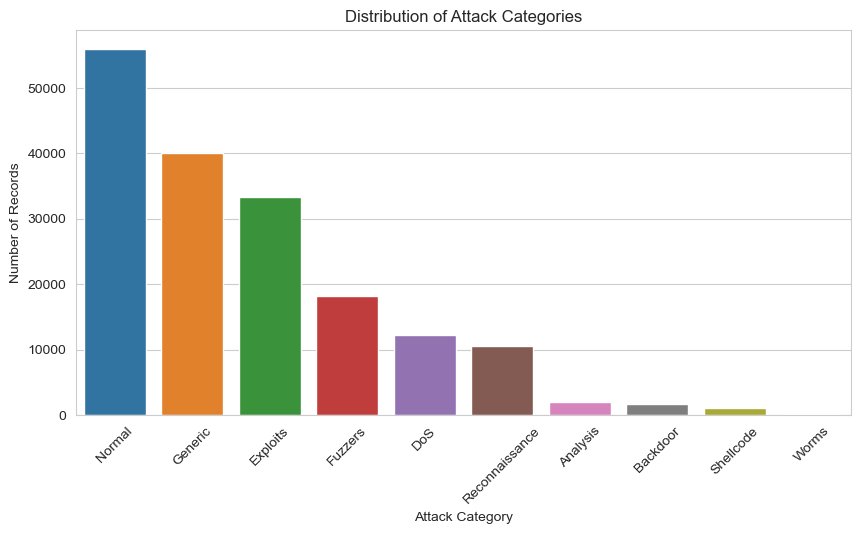

In [18]:
# Visualizing the distribution of attack categories

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='attack_cat',
    order=df['attack_cat'].value_counts().index
)

plt.title('Distribution of Attack Categories')
plt.xlabel('Attack Category')
plt.ylabel('Number of Records')
plt.xticks(rotation=45)

plt.show()

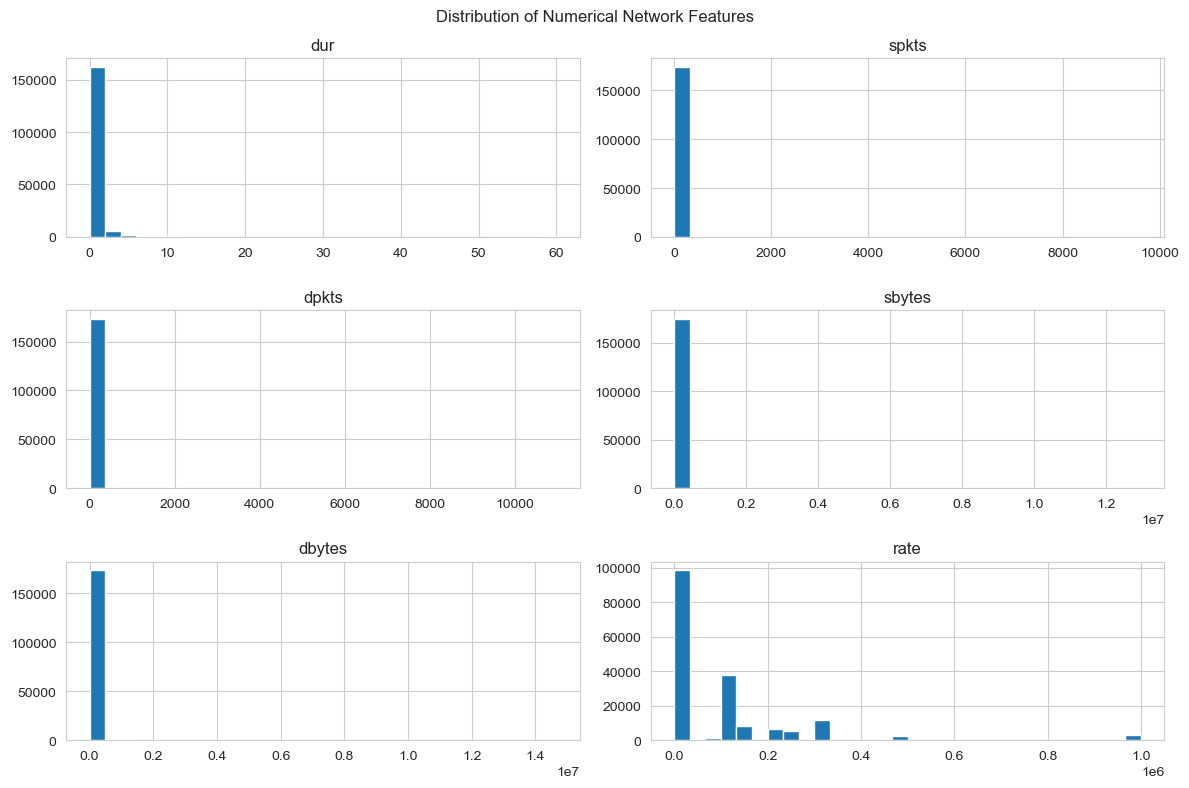

In [19]:
# Visualizing the distribution of numerical features

numerical_features = ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate']

df[numerical_features].hist(figsize=(12, 8), bins=30)

plt.suptitle('Distribution of Numerical Network Features')
plt.tight_layout()
plt.show()

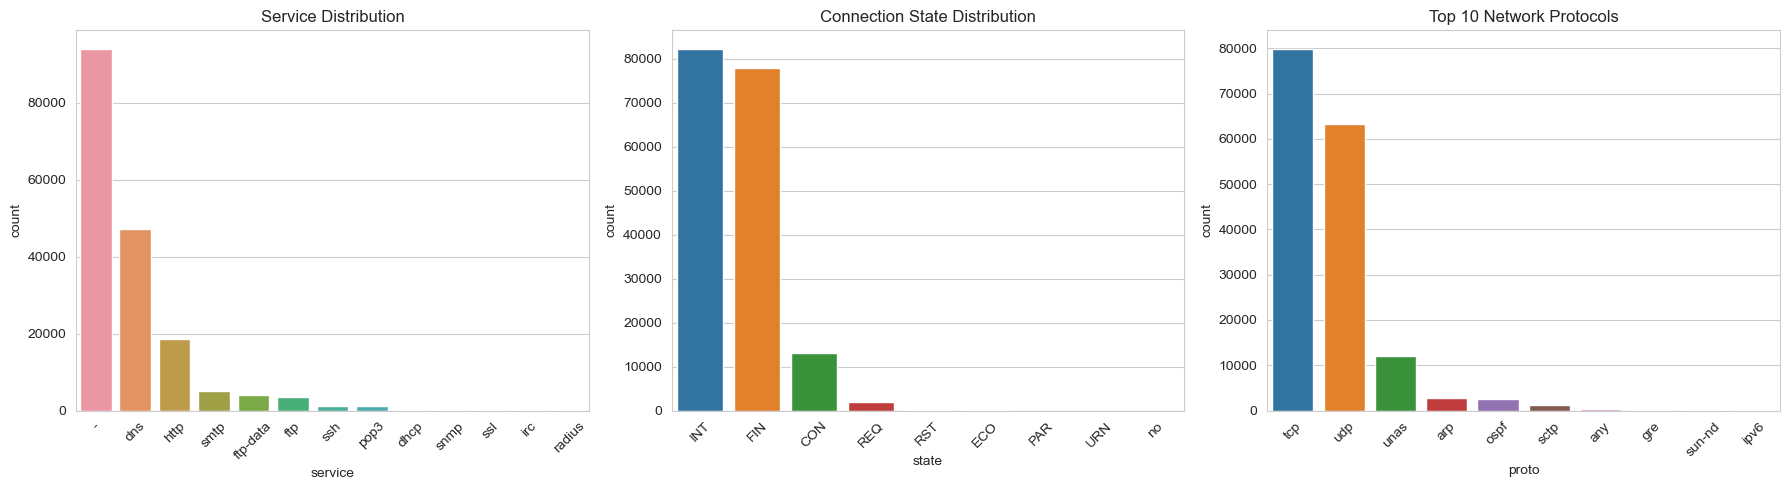

In [20]:
# Visualizing categorical feature distributions

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.countplot(data=df, x='service',
              order=df['service'].value_counts().index, ax=axes[0])
axes[0].set_title('Service Distribution')
axes[0].tick_params(axis='x', rotation=45)

sns.countplot(data=df, x='state',
              order=df['state'].value_counts().index, ax=axes[1])
axes[1].set_title('Connection State Distribution')
axes[1].tick_params(axis='x', rotation=45)

top_protocols = df['proto'].value_counts().head(10).index

sns.countplot(data=df[df['proto'].isin(top_protocols)],
              x='proto', order=top_protocols, ax=axes[2])
axes[2].set_title('Top 10 Network Protocols')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

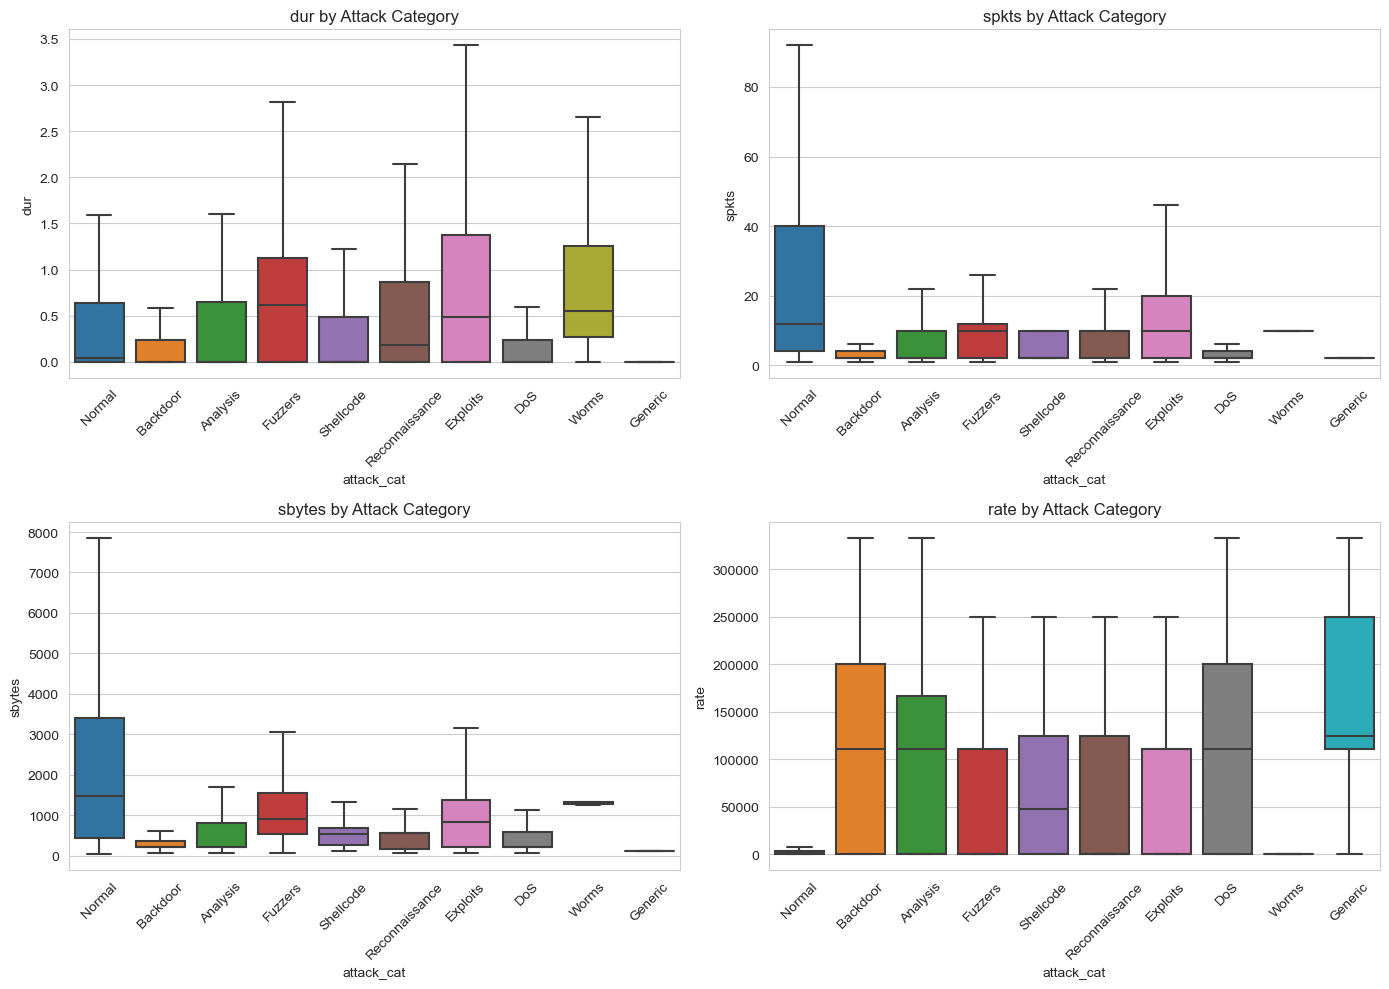

In [22]:
# Comparing central feature distributions across attack categories

features = ['dur', 'spkts', 'sbytes', 'rate']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for feature, ax in zip(features, axes.flatten()):
    sns.boxplot(
        data=df,
        x='attack_cat',
        y=feature,
        showfliers=False,
        ax=ax
    )
    ax.set_title(f'{feature} by Attack Category')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### Feature Engineering

In [3]:
# Separating input features and target variable

X = df.drop(columns=['id', 'label', 'attack_cat'])
y = df['attack_cat']

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (175341, 42)
Target shape: (175341,)


In [4]:
# Splitting the dataset into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (140272, 42)
Testing features: (35069, 42)
Training target: (140272,)
Testing target: (35069,)


In [5]:
# Identifying categorical and numerical features

categorical_features = X_train.select_dtypes(include='object').columns.tolist()
numerical_features = X_train.select_dtypes(include=np.number).columns.tolist()

print("Categorical features:", categorical_features)
print("Number of numerical features:", len(numerical_features))

Categorical features: ['proto', 'service', 'state']
Number of numerical features: 39


In [6]:
# Importing preprocessing tools

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

In [7]:
# Creating preprocessing transformer

preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('numerical', StandardScaler(), numerical_features)
    ]
)

In [8]:
# Creating preprocessing transformer for tree-based models

tree_preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('numerical', 'passthrough', numerical_features)
    ]
)

In [9]:
# Importing LabelEncoder

from sklearn.preprocessing import LabelEncoder

# Encoding target variable

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# Displaying encoded class labels

print("Class labels:", label_encoder.classes_)

Class labels: ['Analysis' 'Backdoor' 'DoS' 'Exploits' 'Fuzzers' 'Generic' 'Normal'
 'Reconnaissance' 'Shellcode' 'Worms']


## Model Building

#### Decision Tree model

In [10]:
# Importing Decision Tree Classifier

from sklearn.tree import DecisionTreeClassifier

# Creating Decision Tree pipeline

dt_model = Pipeline([
    ('preprocessing', tree_preprocessor),
    ('classifier', DecisionTreeClassifier(
        class_weight='balanced',
        random_state=42
    ))
])

In [12]:
# Training Decision Tree model

dt_model.fit(X_train, y_train_encoded)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


In [13]:
# Predicting attack categories

dt_predictions = dt_model.predict(X_test)

print("Predictions generated successfully.")

Predictions generated successfully.


In [14]:
# Importing evaluation metrics

from sklearn.metrics import accuracy_score, classification_report

# Calculating accuracy

dt_accuracy = accuracy_score(y_test_encoded, dt_predictions)

print("Decision Tree Accuracy:", dt_accuracy)

# Generating classification report

print("\nClassification Report:")
print(classification_report(
    y_test_encoded,
    dt_predictions,
    target_names=label_encoder.classes_,
    zero_division=0
))

Decision Tree Accuracy: 0.7522883458325016

Classification Report:
                precision    recall  f1-score   support

      Analysis       0.04      0.14      0.06       400
      Backdoor       0.02      0.17      0.03       349
           DoS       0.29      0.19      0.23      2453
      Exploits       0.84      0.51      0.64      6679
       Fuzzers       0.75      0.68      0.71      3637
       Generic       0.99      0.98      0.99      8000
        Normal       0.92      0.92      0.92     11200
Reconnaissance       0.88      0.73      0.80      2098
     Shellcode       0.69      0.69      0.69       227
         Worms       0.47      0.62      0.53        26

      accuracy                           0.75     35069
     macro avg       0.59      0.56      0.56     35069
  weighted avg       0.84      0.75      0.78     35069



#### Random Forest Classifier

In [17]:
# Importing Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier

# Creating Random Forest pipeline

rf_model = Pipeline([
    ('preprocessing', tree_preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        class_weight='balanced_subsample',
        random_state=42,
        n_jobs=-1
    ))
])

In [18]:
# Training Random Forest model

rf_model.fit(X_train, y_train_encoded)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [19]:
# Predicting attack categories

rf_predictions = rf_model.predict(X_test)

print("Random Forest predictions generated successfully.")

Random Forest predictions generated successfully.


In [21]:
# Calculating accuracy

from sklearn.metrics import accuracy_score, classification_report

rf_accuracy = accuracy_score(y_test_encoded, rf_predictions)

print("Random Forest Accuracy:", rf_accuracy)

# Generating classification report

print("\nClassification Report:")
print(classification_report(
    y_test_encoded,
    rf_predictions,
    target_names=label_encoder.classes_,
    zero_division=0
))

Random Forest Accuracy: 0.7723345404773446

Classification Report:
                precision    recall  f1-score   support

      Analysis       0.11      0.24      0.15       400
      Backdoor       0.03      0.17      0.05       349
           DoS       0.31      0.46      0.37      2453
      Exploits       0.84      0.53      0.65      6679
       Fuzzers       0.66      0.86      0.75      3637
       Generic       1.00      0.98      0.99      8000
        Normal       0.99      0.84      0.91     11200
Reconnaissance       0.83      0.79      0.81      2098
     Shellcode       0.52      0.87      0.65       227
         Worms       0.47      0.54      0.50        26

      accuracy                           0.77     35069
     macro avg       0.58      0.63      0.58     35069
  weighted avg       0.85      0.77      0.80     35069



In [22]:
# Importing XGBoost Classifier

from xgboost import XGBClassifier

# Creating XGBoost pipeline

xgb_model = Pipeline([
    ('preprocessing', tree_preprocessor),
    ('classifier', XGBClassifier(
        objective='multi:softprob',
        num_class=10,
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='mlogloss',
        tree_method='hist',
        random_state=42,
        n_jobs=-1
    ))
])

In [23]:
# Training XGBoost model

xgb_model.fit(X_train, y_train_encoded)

print("XGBoost model trained successfully.")

XGBoost model trained successfully.


In [24]:
# Predicting attack categories

xgb_predictions = xgb_model.predict(X_test)

print("XGBoost predictions generated successfully.")

XGBoost predictions generated successfully.


In [25]:
# Calculating accuracy

xgb_accuracy = accuracy_score(y_test_encoded, xgb_predictions)

print("XGBoost Accuracy:", xgb_accuracy)

# Generating classification report

print("\nClassification Report:")
print(classification_report(
    y_test_encoded,
    xgb_predictions,
    target_names=label_encoder.classes_,
    zero_division=0
))

XGBoost Accuracy: 0.8295645726995352

Classification Report:
                precision    recall  f1-score   support

      Analysis       0.78      0.11      0.19       400
      Backdoor       0.87      0.13      0.22       349
           DoS       0.44      0.08      0.14      2453
      Exploits       0.62      0.94      0.75      6679
       Fuzzers       0.75      0.73      0.74      3637
       Generic       1.00      0.98      0.99      8000
        Normal       0.94      0.92      0.93     11200
Reconnaissance       0.92      0.75      0.82      2098
     Shellcode       0.67      0.72      0.69       227
         Worms       0.53      0.35      0.42        26

      accuracy                           0.83     35069
     macro avg       0.75      0.57      0.59     35069
  weighted avg       0.83      0.83      0.81     35069



In [26]:
# Comparing model performance

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models = {
    'Decision Tree': dt_predictions,
    'Random Forest': rf_predictions,
    'XGBoost': xgb_predictions
}

results = []

for model_name, predictions in models.items():

    results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test_encoded, predictions),
        'Macro Precision': precision_score(
            y_test_encoded, predictions, average='macro', zero_division=0
        ),
        'Macro Recall': recall_score(
            y_test_encoded, predictions, average='macro', zero_division=0
        ),
        'Macro F1-Score': f1_score(
            y_test_encoded, predictions, average='macro', zero_division=0
        ),
        'Weighted F1-Score': f1_score(
            y_test_encoded, predictions, average='weighted', zero_division=0
        )
    })

model_comparison = pd.DataFrame(results)

model_comparison.round(3)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-Score,Weighted F1-Score
0,Decision Tree,0.752,0.588,0.563,0.560,0.784
1,Random Forest,0.772,0.577,0.628,0.583,0.799
2,XGBoost,0.830,0.751,0.569,0.588,0.808


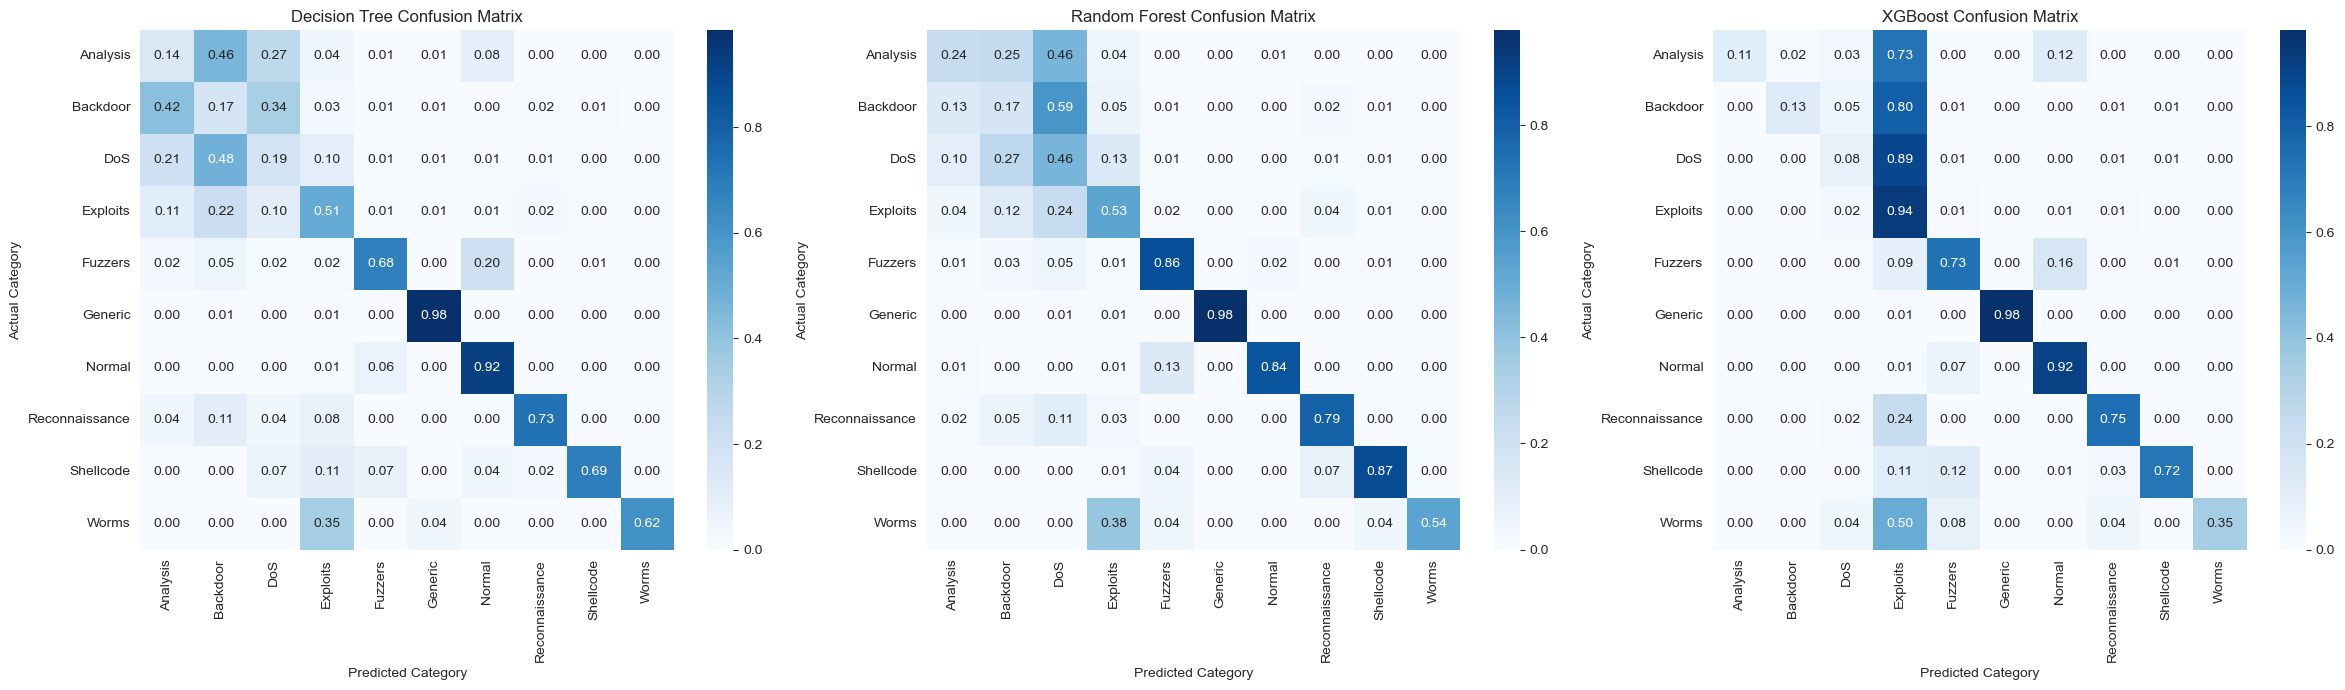

In [27]:
# Comparing confusion matrices

from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 3, figsize=(24, 7))

model_predictions = {
    'Decision Tree': dt_predictions,
    'Random Forest': rf_predictions,
    'XGBoost': xgb_predictions
}

for ax, (name, predictions) in zip(axes, model_predictions.items()):

    cm = confusion_matrix(
        y_test_encoded,
        predictions,
        normalize='true'
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='.2f',
        cmap='Blues',
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
        ax=ax
    )

    ax.set_title(f'{name} Confusion Matrix')
    ax.set_xlabel('Predicted Category')
    ax.set_ylabel('Actual Category')
    ax.tick_params(axis='x', rotation=90)
    ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()

#### Prediction on Unseen Network Traffic

In [28]:
# Selecting 10 unseen records from the test dataset

unseen_data = X_test.sample(n=10, random_state=42)

# Getting the actual attack categories

actual_categories = y_test.loc[unseen_data.index]

# Predicting using Random Forest and XGBoost

rf_unseen_predictions = rf_model.predict(unseen_data)
xgb_unseen_predictions = xgb_model.predict(unseen_data)

# Converting encoded predictions back to original class labels

rf_predictions_labels = label_encoder.inverse_transform(
    rf_unseen_predictions.astype(int)
)

xgb_predictions_labels = label_encoder.inverse_transform(
    xgb_unseen_predictions.astype(int)
)

# Comparing actual and predicted categories

prediction_results = pd.DataFrame({
    'Actual Category': actual_categories.values,
    'Random Forest Prediction': rf_predictions_labels,
    'XGBoost Prediction': xgb_predictions_labels
})

prediction_results

,Actual Category,Random Forest Prediction,XGBoost Prediction
0,Generic,Generic,Generic
1,Exploits,Exploits,Exploits
2,Generic,Generic,Generic
3,Exploits,DoS,Exploits
4,DoS,Backdoor,Exploits
5,Normal,Normal,Normal
6,Normal,Normal,Normal
7,Exploits,Backdoor,Exploits
8,Generic,Generic,Generic
9,Exploits,DoS,Exploits


###  Project Limitations

**Class Imbalance:** The dataset contains an unequal distribution of attack categories. Minority classes such as Worms, Backdoor, and Analysis have fewer records, making them difficult to classify accurately.

**Classification Performance:** The evaluated models show weaker detection performance for certain attack categories, particularly DoS, Backdoor, and Analysis.

 **No Real-Time Deployment:** This project focuses on offline classification of recorded network traffic. It does not implement or evaluate a real-time network intrusion detection system.

### Conclusion

This project focused on developing a machine learning-based network intrusion detection system to classify normal network traffic and identify different categories of cyberattacks using the UNSW-NB15 dataset.

The dataset was explored, cleaned, and preprocessed before training and evaluating three classification algorithms: Decision Tree, Random Forest, and XGBoost.

Among the evaluated models, XGBoost achieved the highest accuracy of 82.96% and macro F1-score of 0.588. Random Forest achieved the highest macro recall of 0.628, demonstrating better overall detection across attack categories. Decision Tree recorded comparatively lower performance.

The evaluation revealed that although the models performed well in identifying certain categories, they struggled with minority attack classes such as Backdoor, Analysis, and DoS. This highlights the impact of class imbalance on multiclass classification performance.

Overall, the project demonstrates the application of machine learning techniques for network intrusion detection and emphasizes the importance of evaluating models using multiple performance metrics. Further improvements in handling class imbalance, feature selection, and model optimization could help enhance attack detection performance.